***Dry Bean Type Classification Project - Lochan Rai***

**Objective**

An agriculture company approaches you with a challenge: they are currently classifying different types of dry beans manually, a process that is labour-intensive, prone to errors and inefficient at scale. They want to automate this classification process using Artificial Intelligence to improve accuracy, reduce operational costs and ensure consistent quality in packaging and distribution.

As a data scientist, your role is to help them build a machine learning solution that can accurately classify bean types based on physical characteristics such as area, perimeter, shape and compactness. By doing this, you'll:

•	Automate the bean classification process using supervised learning techniques

•	Help the company reduce manual labour and cost

•	Improve the speed and reliability of quality control operations

•	Deliver a scalable solution for real-time classification in industrial settings

This project not only enhances your understanding of supervised machine learning but also demonstrates how AI can be directly applied to Agri-tech and food processing industries for tangible business impact.


**DATA DICTIONARY**

1.	Area (A): The area of a bean zone and the number of pixels within its boundaries.
2.	Perimeter (P): Bean circumference is defined as the length of its border.
3.	Major axis length (L): The distance between the ends of the longest line that can be drawn from a bean.
4.	Minor axis length (l): The longest line that can be drawn from the bean while standing perpendicular to the main axis.
5.	Aspect ratio (K): Defines the relationship between L and l.
6.	Eccentricity (Ec): Eccentricity of the ellipse having the same moments as the region.
7.	Convex area (C): Number of pixels in the smallest convex polygon that can contain the area of a bean seed.
8.	Equivalent diameter (Ed): The diameter of a circle having the same area as a bean seed area.
9.	Extent (Ex): The ratio of the pixels in the bounding box to the bean area.
10.	Solidity (S): Also known as convexity. The ratio of the pixels in the convex shell to those found in beans.
11.	Roundness (R): Calculated with the following formula: (4piA)/(P^2)
12.	Compactness (CO): Measures the roundness of an object: Ed/L
13.	ShapeFactor1 (SF1)
14.	ShapeFactor2 (SF2)
15.	ShapeFactor3 (SF3)
16.	ShapeFactor4 (SF4)
17.	Class (Seker, Barbunya, Bombay, Cali, Dermosan, Horoz and Sira) 


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.tree import DecisionTreeClassifier
from sklearn import tree 
from sklearn.model_selection import train_test_split , GridSearchCV
from sklearn.metrics import accuracy_score , confusion_matrix , roc_auc_score , roc_curve

In [2]:
%pip install openpyxl

Note: you may need to restart the kernel to use updated packages.


**1. Import and Load the data**

In [3]:
df= pd.read_excel("C:/Users/LochanRai_lsntoq1/B-15 DS/MiniProject7/Dry_Bean_Dataset.xlsx")
df

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13606,42097,759.696,288.721612,185.944705,1.552728,0.765002,42508,231.515799,0.714574,0.990331,0.916603,0.801865,0.006858,0.001749,0.642988,0.998385,DERMASON
13607,42101,757.499,281.576392,190.713136,1.476439,0.735702,42494,231.526798,0.799943,0.990752,0.922015,0.822252,0.006688,0.001886,0.676099,0.998219,DERMASON
13608,42139,759.321,281.539928,191.187979,1.472582,0.734065,42569,231.631261,0.729932,0.989899,0.918424,0.822730,0.006681,0.001888,0.676884,0.996767,DERMASON
13609,42147,763.779,283.382636,190.275731,1.489326,0.741055,42667,231.653248,0.705389,0.987813,0.907906,0.817457,0.006724,0.001852,0.668237,0.995222,DERMASON


In [4]:
df.head()

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


In [5]:
df.tail()

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
13606,42097,759.696,288.721612,185.944705,1.552728,0.765002,42508,231.515799,0.714574,0.990331,0.916603,0.801865,0.006858,0.001749,0.642988,0.998385,DERMASON
13607,42101,757.499,281.576392,190.713136,1.476439,0.735702,42494,231.526798,0.799943,0.990752,0.922015,0.822252,0.006688,0.001886,0.676099,0.998219,DERMASON
13608,42139,759.321,281.539928,191.187979,1.472582,0.734065,42569,231.631261,0.729932,0.989899,0.918424,0.822730,0.006681,0.001888,0.676884,0.996767,DERMASON
13609,42147,763.779,283.382636,190.275731,1.489326,0.741055,42667,231.653248,0.705389,0.987813,0.907906,0.817457,0.006724,0.001852,0.668237,0.995222,DERMASON
13610,42159,772.237,295.142741,182.204716,1.619841,0.786693,42600,231.686223,0.788962,0.989648,0.888380,0.784997,0.007001,0.001640,0.616221,0.998180,DERMASON


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 13611 entries, 0 to 13610
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             13611 non-null  int64  
 1   Perimeter        13611 non-null  float64
 2   MajorAxisLength  13611 non-null  float64
 3   MinorAxisLength  13611 non-null  float64
 4   AspectRation     13611 non-null  float64
 5   Eccentricity     13611 non-null  float64
 6   ConvexArea       13611 non-null  int64  
 7   EquivDiameter    13611 non-null  float64
 8   Extent           13611 non-null  float64
 9   Solidity         13611 non-null  float64
 10  roundness        13611 non-null  float64
 11  Compactness      13611 non-null  float64
 12  ShapeFactor1     13611 non-null  float64
 13  ShapeFactor2     13611 non-null  float64
 14  ShapeFactor3     13611 non-null  float64
 15  ShapeFactor4     13611 non-null  float64
 16  Class            13611 non-null  str    
dtypes: float64(14), int64(2

In [7]:
round(df.describe(), 2)

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
count,13611.00,13611.00,13611.00,13611.00,13611.00,13611.00,13611.00,13611.00,13611.00,13611.00,13611.00,13611.00,13611.00,13611.0,13611.00,13611.00
mean,53048.28,855.28,320.14,202.27,1.58,0.75,53768.20,253.06,0.75,0.99,0.87,0.80,0.01,0.0,0.64,1.00
std,29324.10,214.29,85.69,44.97,0.25,0.09,29774.92,59.18,0.05,0.00,0.06,0.06,0.00,0.0,0.10,0.00
min,20420.00,524.74,183.60,122.51,1.02,0.22,20684.00,161.24,0.56,0.92,0.49,0.64,0.00,0.0,0.41,0.95
25%,36328.00,703.52,253.30,175.85,1.43,0.72,36714.50,215.07,0.72,0.99,0.83,0.76,0.01,0.0,0.58,0.99
50%,44652.00,794.94,296.88,192.43,1.55,0.76,45178.00,238.44,0.76,0.99,0.88,0.80,0.01,0.0,0.64,1.00
75%,61332.00,977.21,376.50,217.03,1.71,0.81,62294.00,279.45,0.79,0.99,0.92,0.83,0.01,0.0,0.70,1.00
max,254616.00,1985.37,738.86,460.20,2.43,0.91,263261.00,569.37,0.87,0.99,0.99,0.99,0.01,0.0,0.97,1.00


Based on the descriptive statistics shown for 13,611 observations, here are the key insights from bean df:

1. Size-related features show high variability
- Area ranges from 20,420 to 254,616, with a mean of 53,048 and a large standard deviation (29,324).
- Perimeter ranges from 525 to 1,985.
- Major_Axis_Length and Minor_Axis_Length also exhibit substantial spread.
- This indicates the dataset contains beans of significantly different sizes, making size an important distinguishing factor.

2. Area distribution appears right-skewed
- Mean Area (53,048) is noticeably higher than the median (44,652).
- The maximum Area (254,616) is far above the 75th percentile (61,332).
- Suggests the presence of some very large beans (possible outliers).

3. Beans are moderately elongated
- Aspect_Ration has:
- Mean = 1.58
- Median = 1.55
- Range = 1.02 to 2.43
- Most beans are not perfectly round and tend to be somewhat elongated.

4. High eccentricity indicates elliptical shapes
- Eccentricity averages 0.75 (range: 0.22–0.91).
- Values closer to 1 represent elongated ellipses.
- Many beans are oval rather than circular.

5. Convex_Area closely follows Area
- Mean Convex_Area = 53,768 versus Mean Area = 53,048.
- Small differences imply most bean boundaries are relatively smooth with limited indentations.

6. Strong solidity across observations
- Solidity mean = 0.987
- Very low standard deviation (0.0047).
- Nearly all beans are highly compact without major concavities.

7. Roundness is fairly consistent
- Mean Roundness = 0.873
- Most values fall between 0.832 and 0.917.
- Suggests many beans maintain a reasonably rounded appearance despite shape differences.

8. Extent has low variation
- Mean Extent = 0.750
- Standard deviation only 0.049
- Indicates a fairly consistent proportion of occupied bounding-box area across beans.

9. Shape factors are relatively stable
- Shape_Factor_1–4 have small standard deviations.
- Particularly Shape_Factor_4:
- Mean = 0.995
- Std = 0.004
- These engineered features appear highly consistent and may be useful for distinguishing subtle shape differences.

10. Potential outliers exist
- Several variables have maximum values far beyond the 75th percentile:
- Area
- Perimeter
- Major_Axis_Length
- Minor_Axis_Length
- Outlier detection may be worthwhile before modeling.
- Overall Conclusion

Conclusion:

The dataset exhibits substantial variation in bean size but much less variation in shape compactness. Features such as Area, Perimeter, Major_Axis_Length, Minor_Axis_Length, Aspect_Ration, and Eccentricity are likely to be the most informative for differentiating bean types, while Solidity, Extent, and Shape_Factor_4 show high consistency across observations.

In [8]:
df.describe(include='object').T

C:\Users\LochanRai_lsntoq1\AppData\Local\Temp\ipykernel_3848\1760094569.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include='object').T


,count,unique,top,freq
Class,13611,7,DERMASON,3546


In [9]:
df['Class'].value_counts()

Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1928
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64

In [10]:
df_num = round(df.select_dtypes(include=np.number),2)


In [11]:
df_num

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
0,28395,610.29,208.18,173.89,1.20,0.55,28715,190.14,0.76,0.99,0.96,0.91,0.01,0.0,0.83,1.00
1,28734,638.02,200.52,182.73,1.10,0.41,29172,191.27,0.78,0.98,0.89,0.95,0.01,0.0,0.91,1.00
2,29380,624.11,212.83,175.93,1.21,0.56,29690,193.41,0.78,0.99,0.95,0.91,0.01,0.0,0.83,1.00
3,30008,645.88,210.56,182.52,1.15,0.50,30724,195.47,0.78,0.98,0.90,0.93,0.01,0.0,0.86,0.99
4,30140,620.13,201.85,190.28,1.06,0.33,30417,195.90,0.77,0.99,0.98,0.97,0.01,0.0,0.94,1.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13606,42097,759.70,288.72,185.94,1.55,0.77,42508,231.52,0.71,0.99,0.92,0.80,0.01,0.0,0.64,1.00
13607,42101,757.50,281.58,190.71,1.48,0.74,42494,231.53,0.80,0.99,0.92,0.82,0.01,0.0,0.68,1.00
13608,42139,759.32,281.54,191.19,1.47,0.73,42569,231.63,0.73,0.99,0.92,0.82,0.01,0.0,0.68,1.00
13609,42147,763.78,283.38,190.28,1.49,0.74,42667,231.65,0.71,0.99,0.91,0.82,0.01,0.0,0.67,1.00


In [12]:
df_cat = df.select_dtypes(include='object')

C:\Users\LochanRai_lsntoq1\AppData\Local\Temp\ipykernel_3848\2702212049.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df_cat = df.select_dtypes(include='object')


In [13]:
df_cat

,Class
0,SEKER
1,SEKER
2,SEKER
3,SEKER
4,SEKER
...,...
13606,DERMASON
13607,DERMASON
13608,DERMASON
13609,DERMASON


In [14]:
df_cat.nunique()

Class    7
dtype: int64

In [15]:
df["Class"].unique()

<ArrowStringArray>
['SEKER', 'BARBUNYA', 'BOMBAY', 'CALI', 'HOROZ', 'SIRA', 'DERMASON']
Length: 7, dtype: str

**2. EDA**

•	Visualize distributions of features using histograms and boxplots

•	Analyze the class distribution (check for class imbalance)

•	Plot feature correlations (eg heatmap)

•	Visualize multivariate relationships (pairplot)

•	Summarize key findings

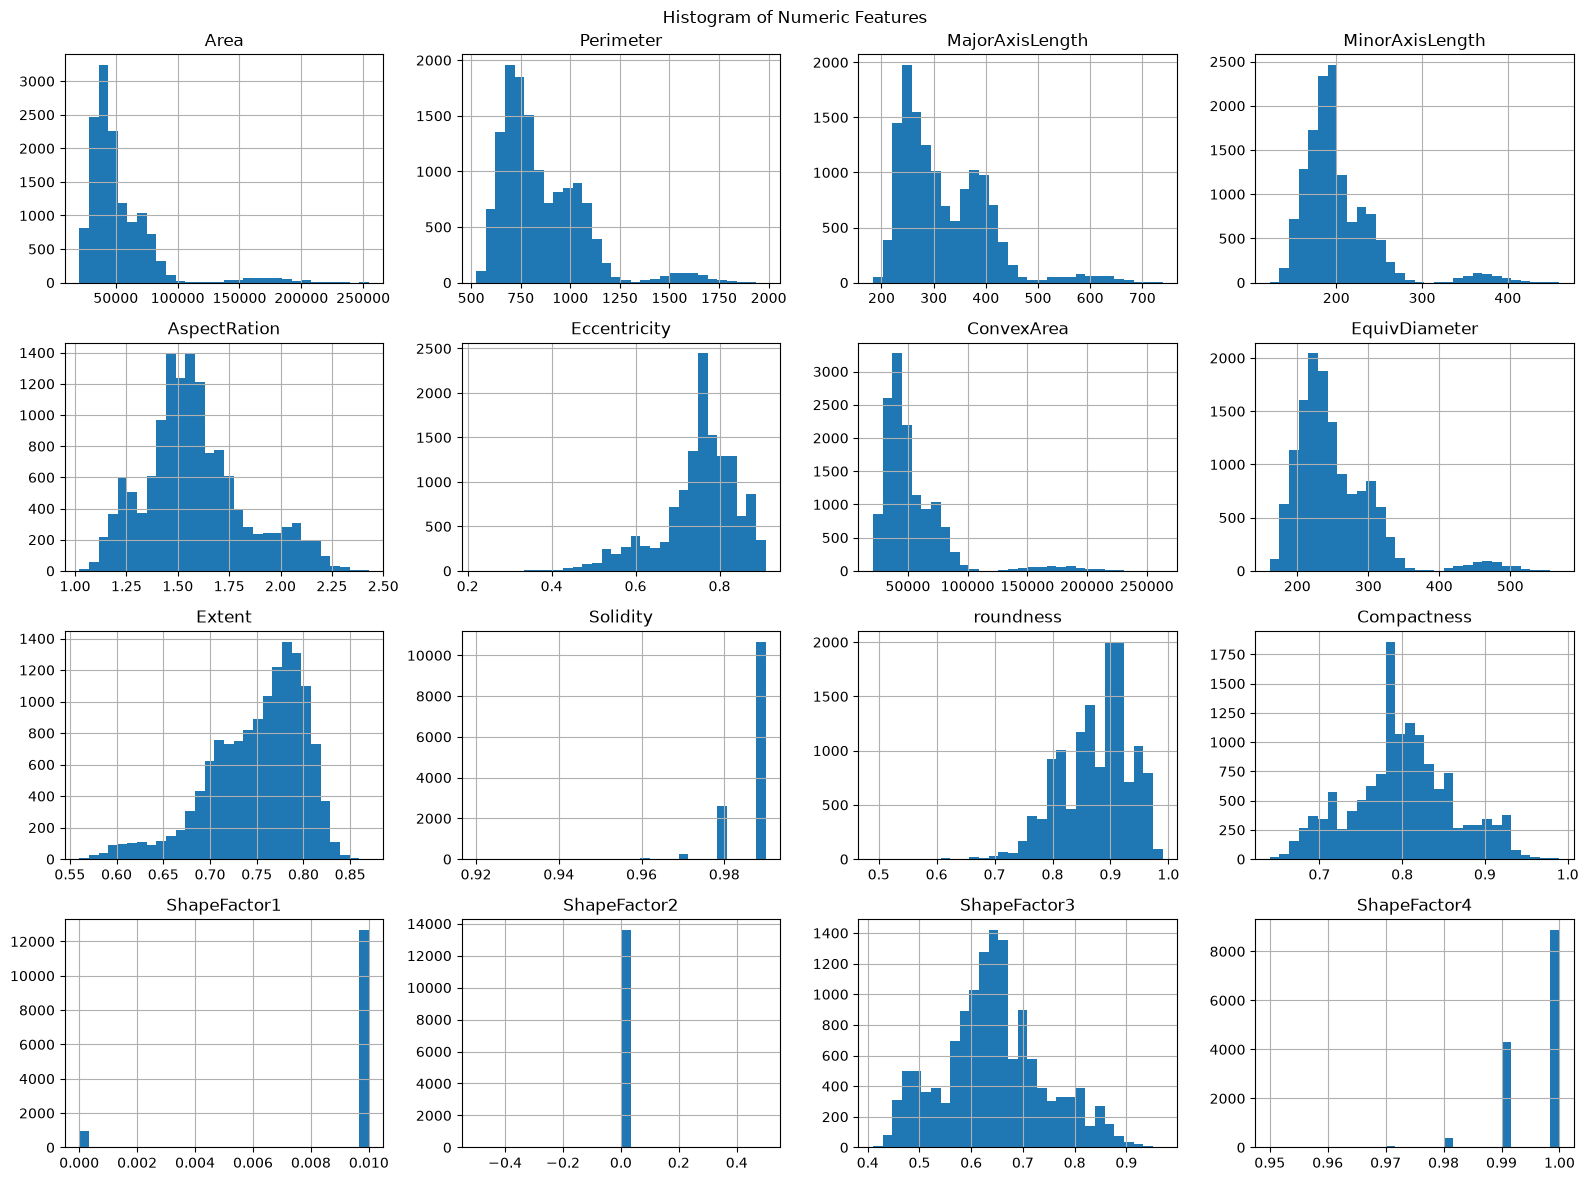

BOXPLOTS OF NUMERIC FEATURES


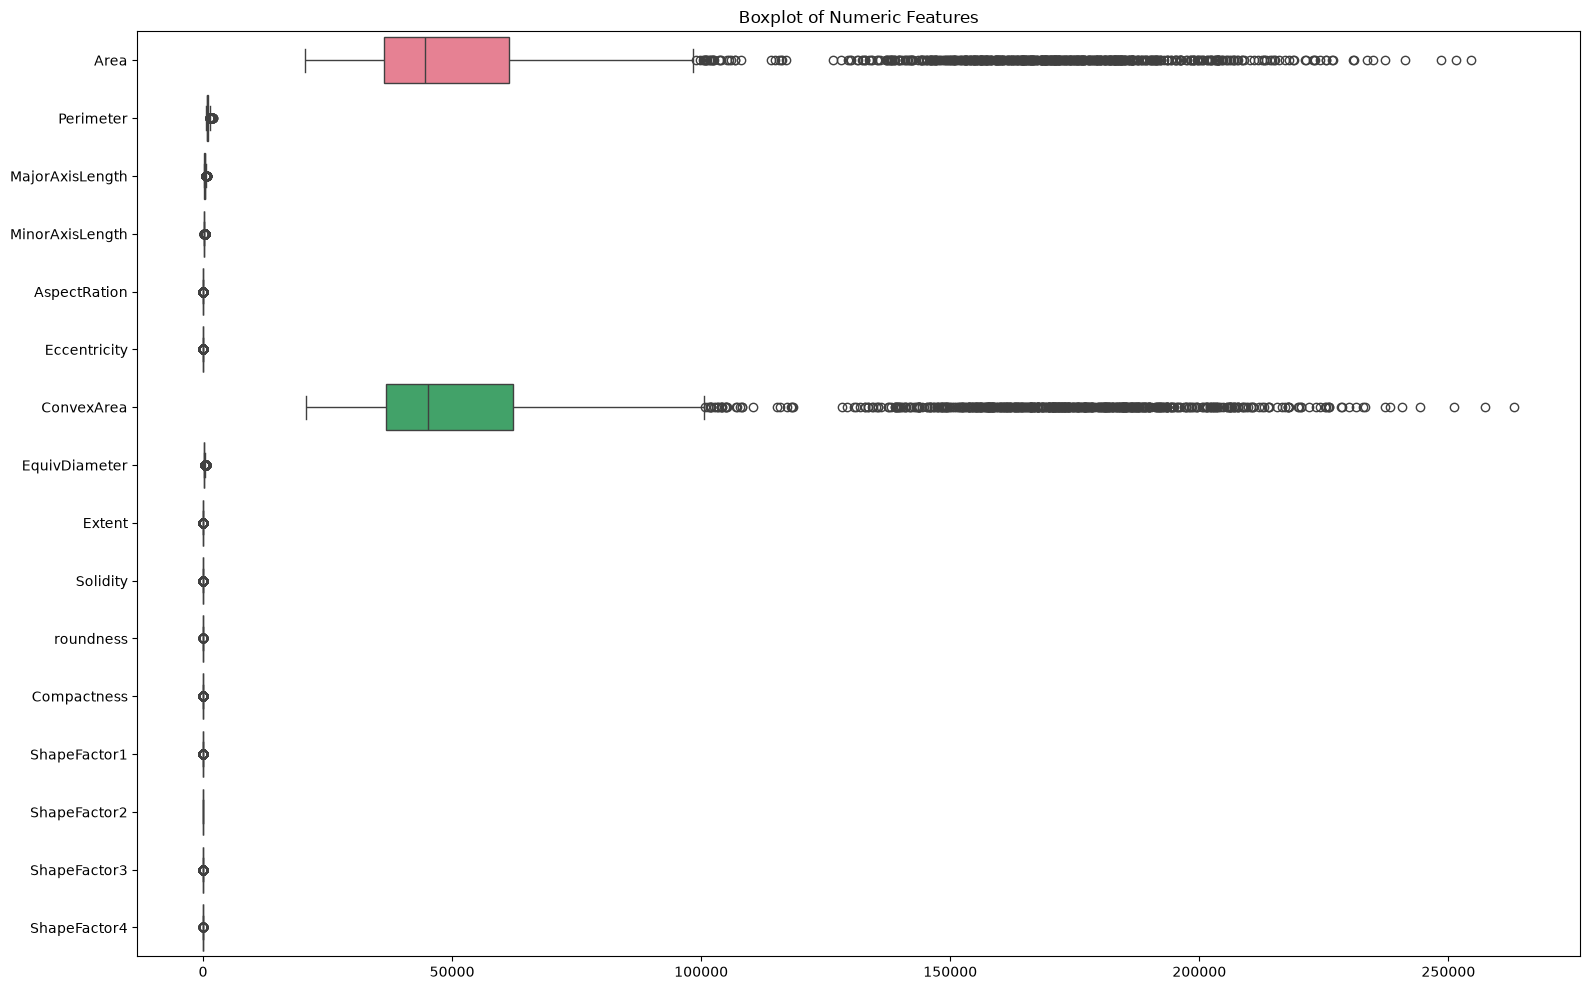

C:\Users\LochanRai_lsntoq1\AppData\Local\Temp\ipykernel_3848\1826584806.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(df, x="Class", palette="Set2",order=df['Class'].value_counts().index)


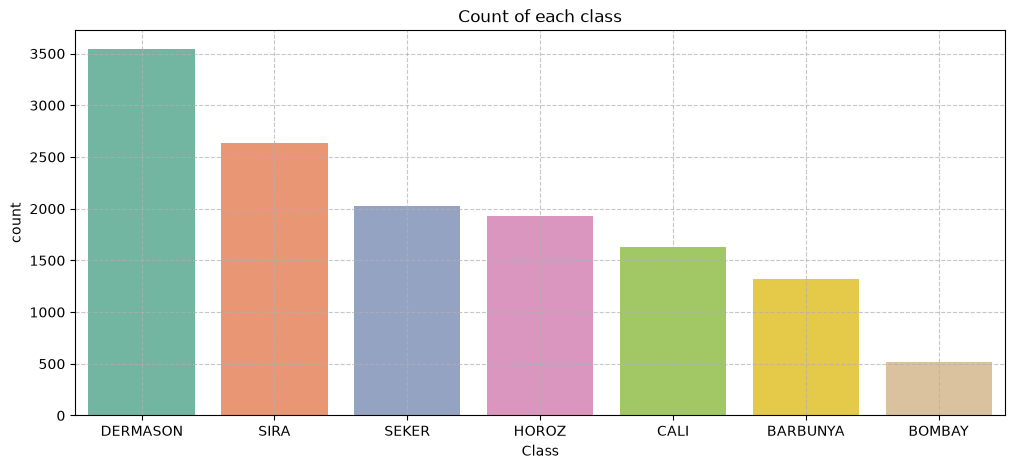

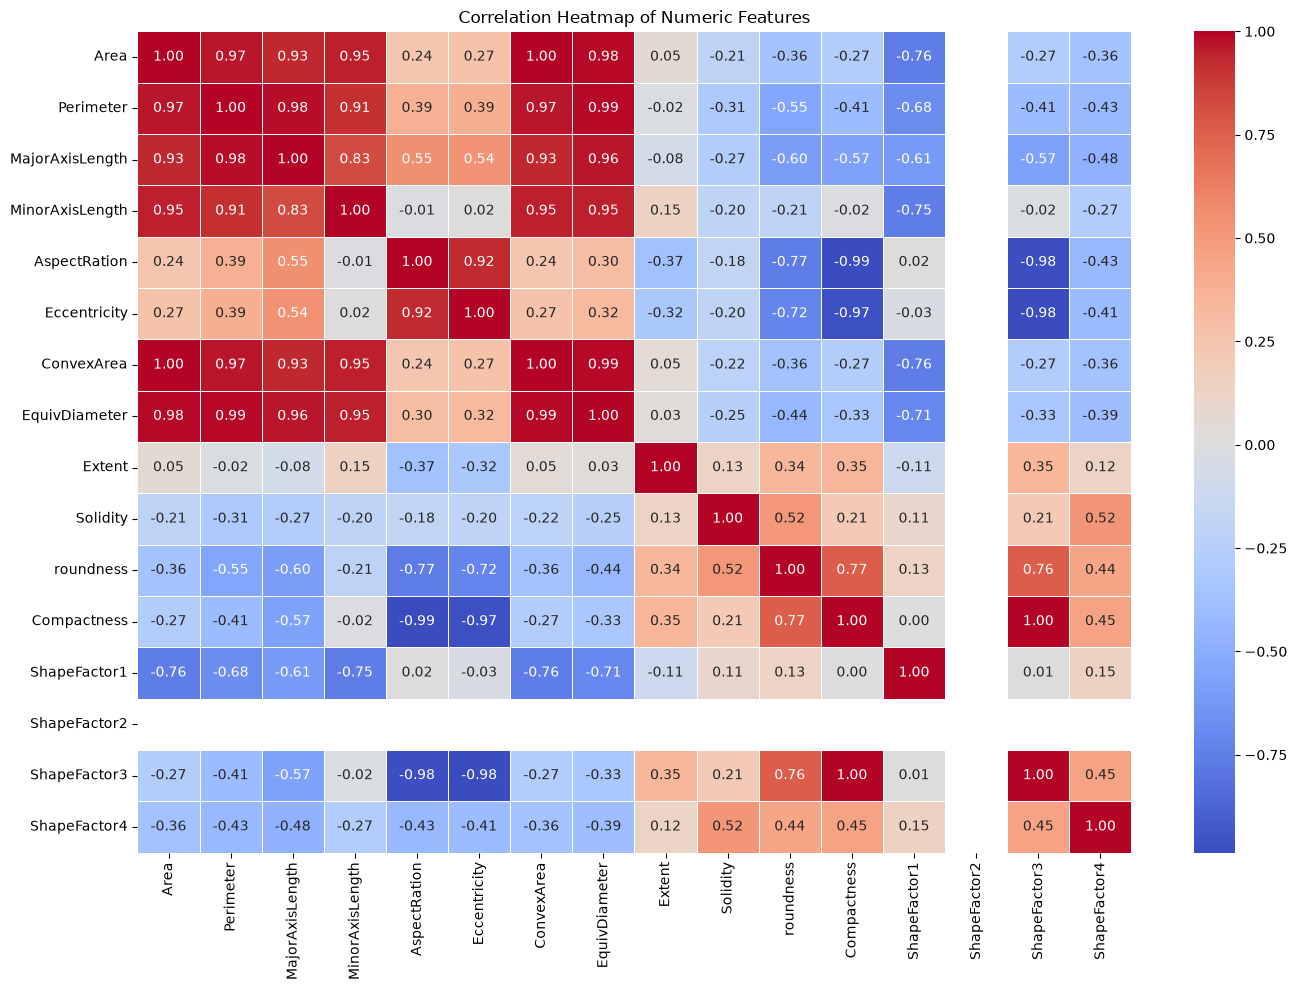

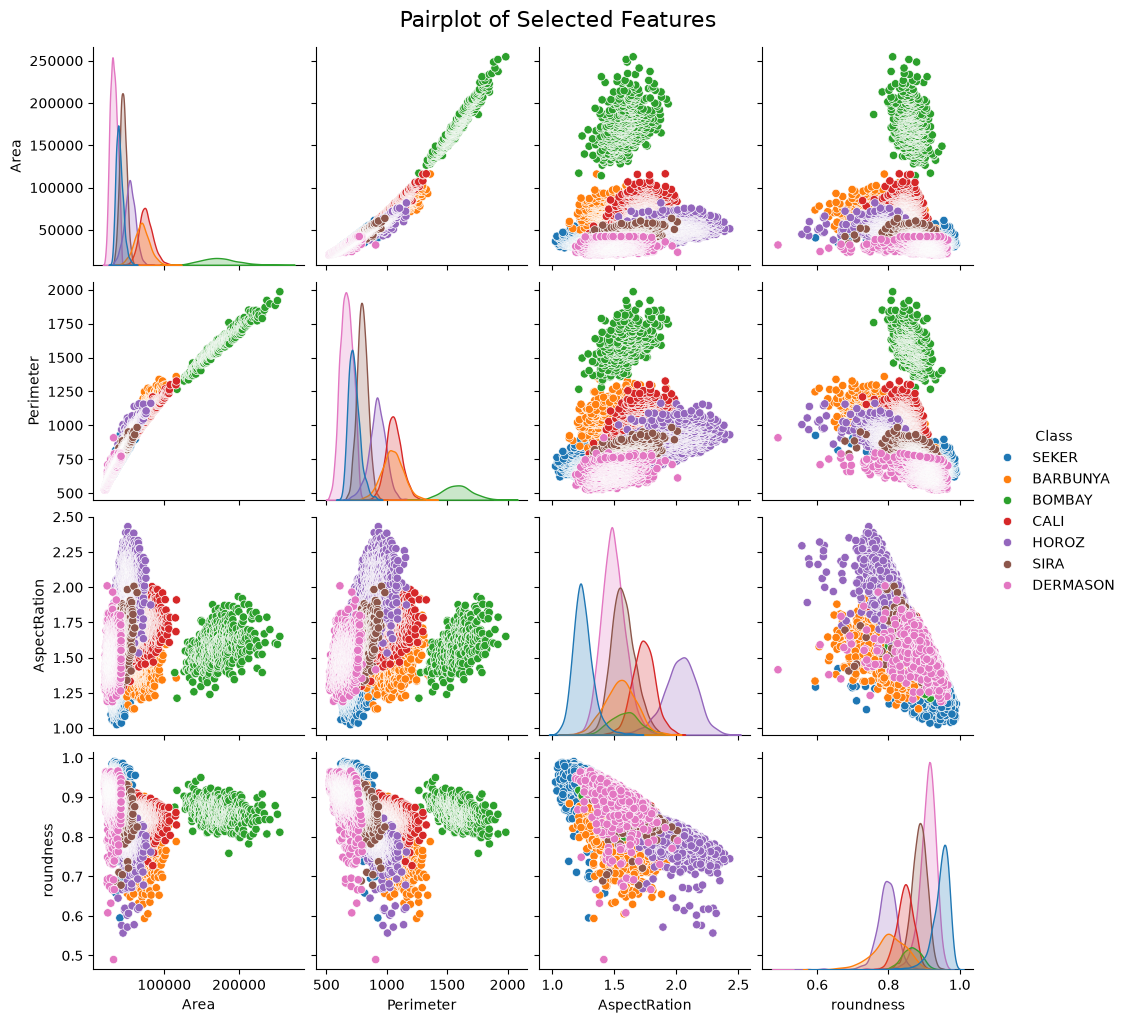

In [16]:
# Creating Histograms of numeric features.

df_num.hist(bins=30, figsize=(16,12))
plt.suptitle('Histogram of Numeric Features')
plt.tight_layout()
plt.show()

# Creating Boxplots to visualize distribution and identify outliers.
print("BOXPLOTS OF NUMERIC FEATURES")
plt.figure(figsize=(16,10))
sns.boxplot(data=df_num, orient='h')
plt.title('Boxplot of Numeric Features')
plt.tight_layout()
plt.show()


# plot class distribution
plt.figure(figsize=(12, 5))
sns.countplot(df, x="Class", palette="Set2",order=df['Class'].value_counts().index)
plt.title("Count of each class")
plt.grid(linestyle='--', alpha=0.7)
plt.show()

# plot feature correlation heatmap

plt.figure(figsize=(14, 10))
correlation_matrix = df_num.corr()
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap of Numeric Features")
plt.tight_layout()
plt.show()

# Visualizing multivariate relationships (pairplots of selected features)

selected_features=cols =['Area', 'Perimeter', 'AspectRation', 'roundness', 'Class']
sns.pairplot(df[selected_features], hue='Class')
plt.suptitle('Pairplot of Selected Features', y= 1.02, fontsize= 16)
plt.show()

#### EDA Analysis.

1. **Class Distribution (Imbalance)**.
    - **DERMASON** (26.1%) and **SIRA** (19.4%) are the most dominant bean classes in the dataset.
    - **BOMBAY** is the rarest class, representing only **3.8%** of the dataset for (522 instances).
    - Moderate Class imbalance is present.

3. **Feature Distribution & Outliers**:
   - Most geometric features (eg. 'Area', 'Perimeter', 'Convex_Area', 'Equiv_Diameter')are **Right-Skewed**.
   - The boxplots indicate a large number of outliers. These outliers are primarily driven by the **BOMBAY** bean class, which is exceptionally larger than all other bean varieties.

4. **Feature Correlation & Multicolinearity**:
   - High positive correlations (near 1.00) exist size-related attributes (eg. 'Area', 'Perimeter', 'Major_Axis_Length', 'Minor_Axis_Length', 'Convex_Area', 'Equiv_Diameter').
   - Strong negative correlations exist between shape factors (like 'Eccentricity') and roundness measures.
   - *Impact*: Tree-based models (such as LightBGM and XGBoost) handle multicolinearity robustly, but feature selection or scaling could be beneficial for simpler distance-based models.

5. **Class Separability**:
   - Simple visual inspections (like the pairplot of'Area' vs' 'Roundness' and'AspectRation') show that certain classes like **BOMBAY** can be linearly separated using area alone.
   - Overlapping boundaries between classes like **SIRA** AND **DERMASON** will require non-linear decision boundaries, making advanced classifiers like Gradient Boosting models ideal candidates.

**3. Missing Value and outlier treatment**

In [17]:
df.isnull().sum()

Area               0
Perimeter          0
MajorAxisLength    0
MinorAxisLength    0
AspectRation       0
Eccentricity       0
ConvexArea         0
EquivDiameter      0
Extent             0
Solidity           0
roundness          0
Compactness        0
ShapeFactor1       0
ShapeFactor2       0
ShapeFactor3       0
ShapeFactor4       0
Class              0
dtype: int64

> No missing value present

In [18]:
# checking duplicates in the dataset
df.duplicated().sum()

np.int64(68)

In [19]:
# Removing Duplicates from the dataset
df.drop_duplicates(inplace=True)

C:\Users\LochanRai_lsntoq1\AppData\Local\Temp\ipykernel_3848\3424958050.py:2: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop_duplicates(inplace=True)


> 68 duplicates found and removed

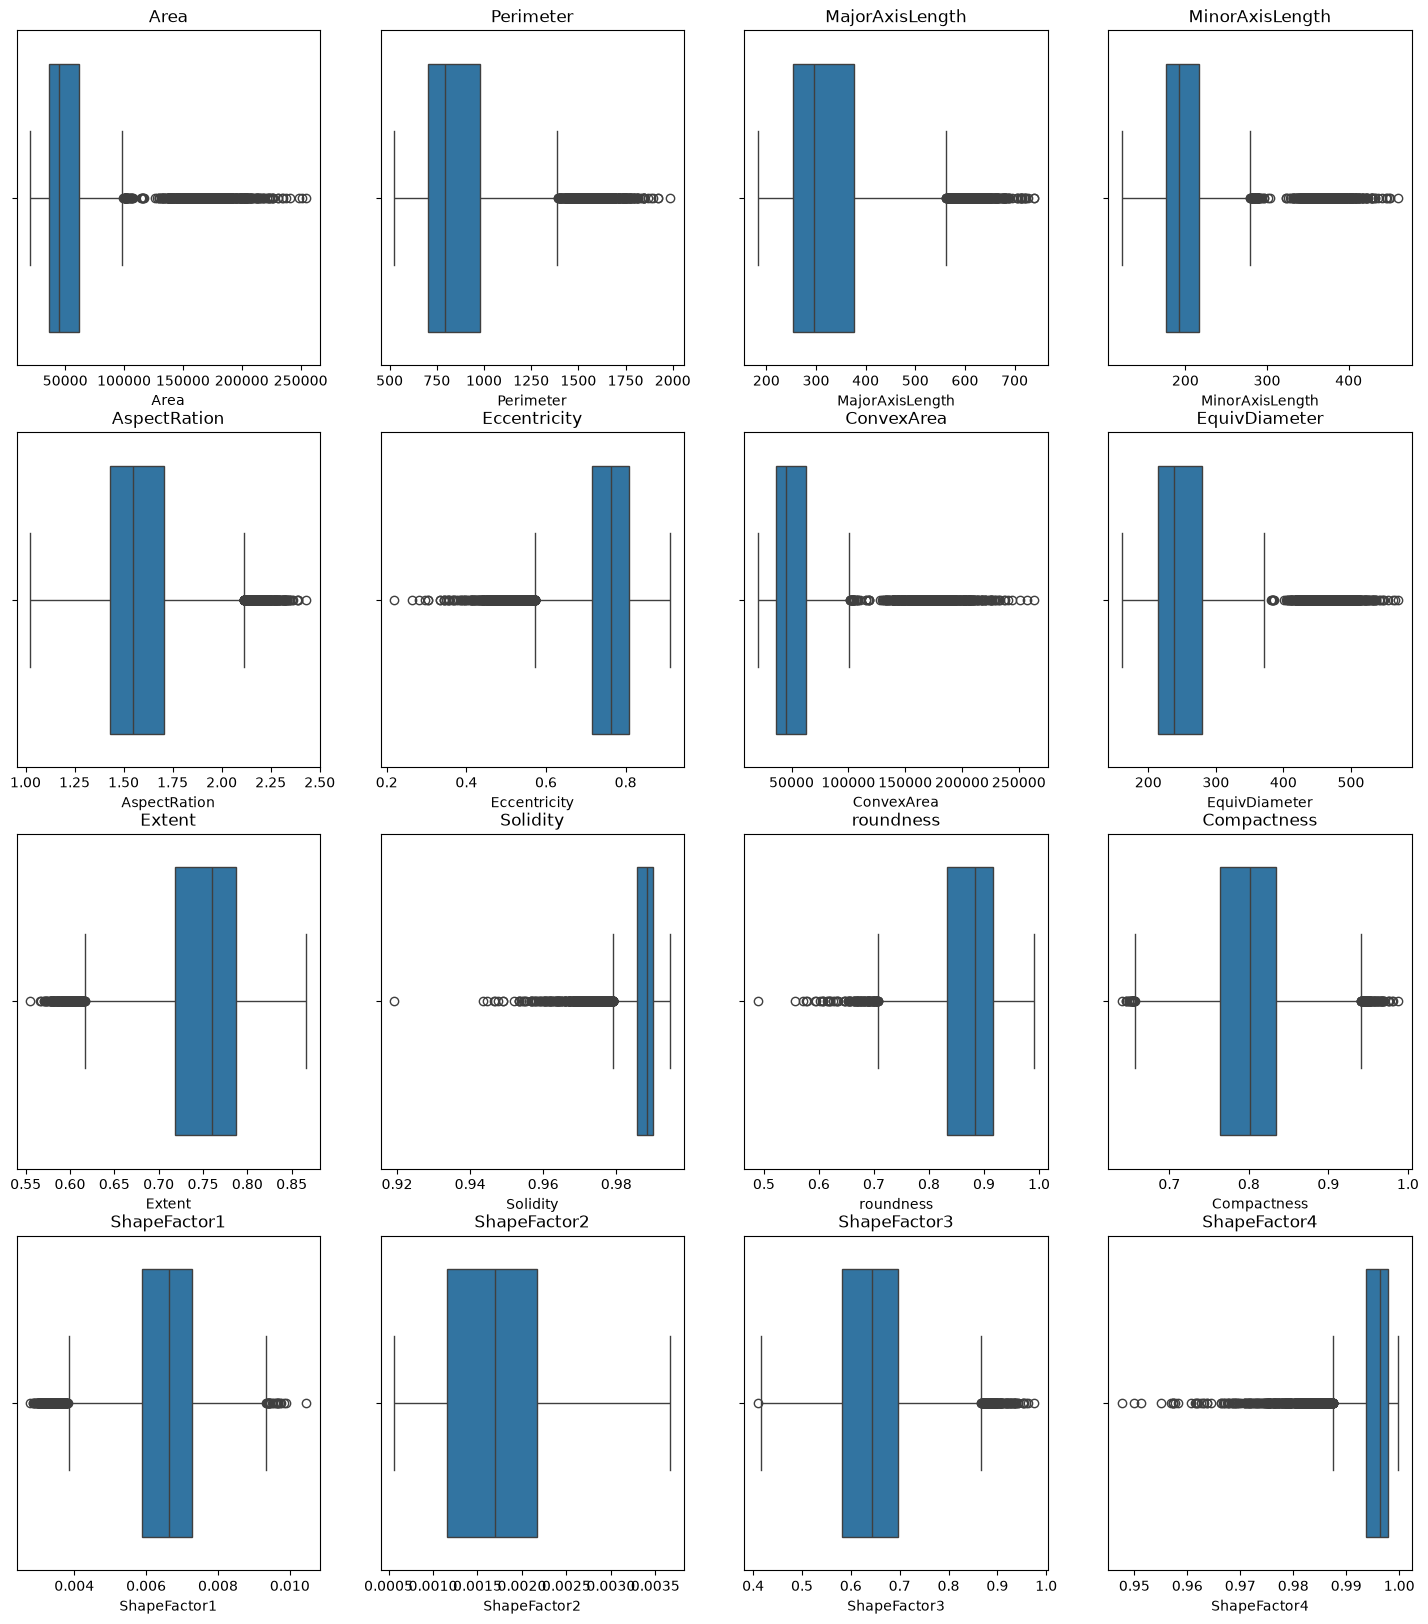

In [20]:
# checking outliers using boxplots for each numeric feature
cols = [col for col in df.columns if col != 'Class']
figure, axes = plt.subplots(4, 4, figsize=(18, 20))
for i, ax in enumerate(axes.flatten()):
    sns.boxplot(data=df, x=cols[i], ax=ax)
    ax.set_title(cols[i])

In [21]:
# using capping for outliers treatment

def bound(col):
  q1,q3=np.quantile(col,[0.25,0.75])
  iqr = q3-q1
  lb = q1-1.5*iqr
  ub = q3 +1.5*iqr
  return lb,ub

In [22]:
bound(df['Area'])

(np.float64(-1366.75), np.float64(99031.25))

In [23]:
# capping col values with ub and lb

values = [col for col in df.columns if col != 'Class']
for i in values:
  if i in df.columns:
    lb, ub = bound(df[i])
    df[i] = np.where(df[i] < lb, lb, df[i])
    df[i] = np.where(df[i] > ub, ub, df[i])

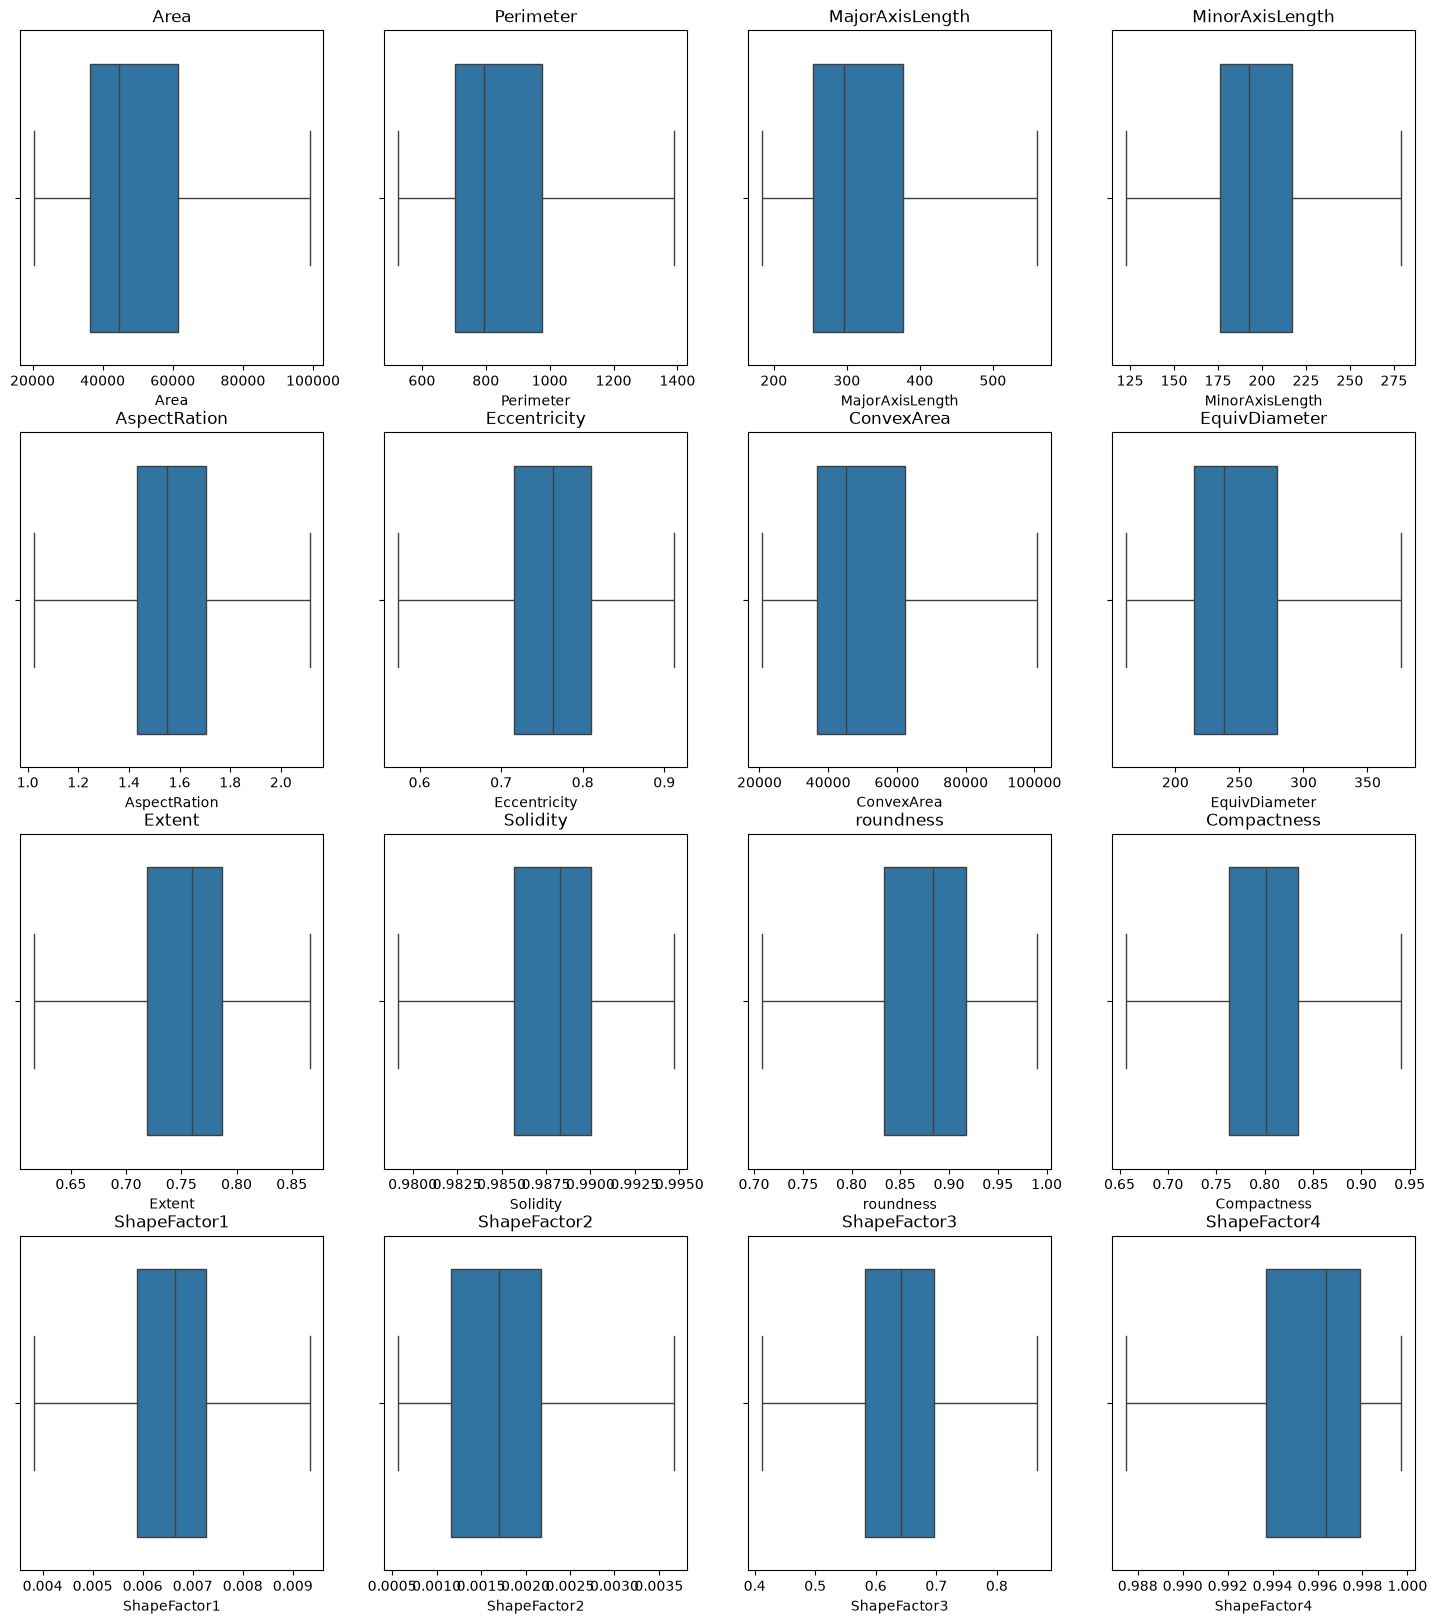

In [24]:
# checking outliersafter capping 

cols = [col for col in df.columns if col != 'Class']
figure, axes = plt.subplots(4, 4, figsize=(18, 20))
for i, ax in enumerate(axes.flatten()):
    sns.boxplot(data=df, x=cols[i], ax=ax)
    ax.set_title(cols[i])

In [25]:
# checking skewness 

initial_skewness = df_num.skew()
print("Initial Skewness:")
print(initial_skewness)

Initial Skewness:
Area               2.952931
Perimeter          1.626124
MajorAxisLength    1.357815
MinorAxisLength    2.238213
AspectRation       0.582910
Eccentricity      -1.063514
ConvexArea         2.941821
EquivDiameter      1.948957
Extent            -0.893439
Solidity          -2.501585
roundness         -0.632571
Compactness        0.038362
ShapeFactor1      -3.397236
ShapeFactor2            NaN
ShapeFactor3       0.242651
ShapeFactor4      -1.565653
dtype: float64


In [26]:
skewness_after_capping = df[cols].skew()
skewness_after_capping

Area               0.962041
Perimeter          0.966336
MajorAxisLength    0.978854
MinorAxisLength    0.729091
AspectRation       0.470467
Eccentricity      -0.614243
ConvexArea         0.969221
EquivDiameter      0.839585
Extent            -0.782121
Solidity          -0.844469
roundness         -0.497000
Compactness        0.017507
ShapeFactor1      -0.332581
ShapeFactor2       0.294332
ShapeFactor3       0.191359
ShapeFactor4      -1.039942
dtype: float64

In [27]:
# Identifying the heavily skewed features (skewness absolute value > 0.75).

skewed_features = skewness_after_capping[abs(skewness_after_capping) > 0.75]
print(f"\nFeatures identified for transformation (skewness > 0.75):")
print(skewed_features.sort_values(ascending=False))


Features identified for transformation (skewness > 0.75):
MajorAxisLength    0.978854
ConvexArea         0.969221
Perimeter          0.966336
Area               0.962041
EquivDiameter      0.839585
Extent            -0.782121
Solidity          -0.844469
ShapeFactor4      -1.039942
dtype: float64


In [28]:
# treating skewness using log transformation for positive skewed features and square root transformation for negative skewed features

import statistics as stats
from scipy.stats import boxcox

# Box-Cox Transformation

transformed_df = df.copy()
for col in skewed_features.index:
    transformed_df[f'{col}'], _= boxcox(df[col] +1) # Adding 1 to avoid log(0) 

# Checking for new skewness for transformed features.
post_skewness = {col: transformed_df[f'{col}'].skew() for col in skewed_features.index}
print("\nSkewness after Box-Cox Transformation:\n")
for col, skew_val in post_skewness.items():
    print(f"{col}_box-cox: {skew_val:.3f}")



Skewness after Box-Cox Transformation:

Area_box-cox: 0.038
Perimeter_box-cox: 0.064
MajorAxisLength_box-cox: 0.075
ConvexArea_box-cox: 0.040
EquivDiameter_box-cox: 0.041
Extent_box-cox: -0.089
Solidity_box-cox: -0.099
ShapeFactor4_box-cox: -0.225


**4. Feature Engineering & Preprocessing**

•   Scale numerical features (StandardScaler / MinMaxScaler)

•	Encode categorical variables if necessary

•	Check and treat skewness if required

•	Split data into train/test sets (use stratified sampling while splitting)

In [29]:
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split

# 1. Separating the features and target from the transformed DataFrame

X = transformed_df.drop(columns=['Class'])
y = transformed_df['Class']

# 2. Encoding the categorical target variable 'Class'.

label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)


# 3. Spliting the data into train and test sets using the stratified sampling method.

X_train, X_test, y_train, y_test = train_test_split(X,y_encoded,test_size=0.2,random_state=23,stratify=y_encoded)

# 4. Scaling the test and training features using StandardScaler.

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [30]:
# Verifying the preprocessing results

print(f"Original dataset shape: {X.shape}")
print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")
print("\nEncoded Target Classes:")
for index, label in enumerate(label_encoder.classes_):
    print(f"{index}:{label}")

Original dataset shape: (13543, 16)
Training set shape: (10834, 16)
Testing set shape: (2709, 16)

Encoded Target Classes:
0:BARBUNYA
1:BOMBAY
2:CALI
3:DERMASON
4:HOROZ
5:SEKER
6:SIRA


In [31]:
training_scores = []
testing_scores = []

In [32]:
def evaluate_model(model,x_train, y_train, x_test, y_test):
    model.fit(x_train, y_train)
    y_train_pred = model.predict(x_train)
    y_test_pred = model.predict(x_test)
    
    training_accuracy = accuracy_score(y_train, y_train_pred)
    testing_accuracy = accuracy_score(y_test, y_test_pred)
    
    training_scores.append(training_accuracy)
    testing_scores.append(testing_accuracy)

    from sklearn.metrics import classification_report, confusion_matrix
    report_test = classification_report(y_test, y_test_pred)
    print(report_test)
    
    print(f"Training Accuracy: {training_accuracy:.4f}")
    print(f"Testing Accuracy: {testing_accuracy:.4f}")

**1. Logistic Regression**

In [33]:
from sklearn.linear_model import LogisticRegression
evaluate_model(
    model=LogisticRegression(),
    x_train=X_train_scaled,
    y_train=y_train,
    x_test=X_test_scaled,
    y_test=y_test
)

              precision    recall  f1-score   support

           0       0.97      0.92      0.94       265
           1       1.00      1.00      1.00       104
           2       0.94      0.97      0.95       326
           3       0.92      0.89      0.91       709
           4       0.97      0.95      0.96       372
           5       0.94      0.95      0.95       406
           6       0.83      0.87      0.85       527

    accuracy                           0.92      2709
   macro avg       0.94      0.94      0.94      2709
weighted avg       0.92      0.92      0.92      2709

Training Accuracy: 0.9271
Testing Accuracy: 0.9217


c:\Users\LochanRai_lsntoq1\B-15 DS\MiniProject7\proj7venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


**2. Random Forest Classifier**

In [34]:
# Evaluate Random Forest Classifier using the function
from sklearn.ensemble import RandomForestClassifier
evaluate_model(
    model=RandomForestClassifier(),
    x_train=X_train_scaled,
    y_train=y_train,
    x_test=X_test_scaled,
    y_test=y_test
)

              precision    recall  f1-score   support

           0       0.95      0.92      0.93       265
           1       1.00      1.00      1.00       104
           2       0.94      0.96      0.95       326
           3       0.90      0.92      0.91       709
           4       0.99      0.94      0.96       372
           5       0.94      0.93      0.94       406
           6       0.85      0.88      0.87       527

    accuracy                           0.92      2709
   macro avg       0.94      0.93      0.94      2709
weighted avg       0.92      0.92      0.92      2709

Training Accuracy: 0.9999
Testing Accuracy: 0.9225


In [35]:
# Evaluate Random Forest Classifier hypertuning
from sklearn.ensemble import RandomForestClassifier
evaluate_model(
    model=RandomForestClassifier(n_estimators=100, max_depth=10, min_samples_split=5, random_state=23),
    x_train=X_train_scaled,
    y_train=y_train,
    x_test=X_test_scaled,
    y_test=y_test
)

              precision    recall  f1-score   support

           0       0.95      0.90      0.93       265
           1       0.98      1.00      0.99       104
           2       0.93      0.94      0.94       326
           3       0.91      0.91      0.91       709
           4       0.98      0.94      0.96       372
           5       0.94      0.93      0.94       406
           6       0.85      0.88      0.86       527

    accuracy                           0.92      2709
   macro avg       0.93      0.93      0.93      2709
weighted avg       0.92      0.92      0.92      2709

Training Accuracy: 0.9617
Testing Accuracy: 0.9195


**3. Decision Tree Classifier**

In [36]:
# Evaluate Decision Tree Classifier using the function
from sklearn.tree import DecisionTreeClassifier
evaluate_model(
    model= DecisionTreeClassifier(),
    x_train=X_train_scaled,
    y_train=y_train,
    x_test=X_test_scaled,
    y_test=y_test
)

              precision    recall  f1-score   support

           0       0.90      0.89      0.90       265
           1       1.00      1.00      1.00       104
           2       0.90      0.93      0.91       326
           3       0.90      0.88      0.89       709
           4       0.95      0.91      0.93       372
           5       0.91      0.93      0.92       406
           6       0.81      0.84      0.82       527

    accuracy                           0.89      2709
   macro avg       0.91      0.91      0.91      2709
weighted avg       0.90      0.89      0.90      2709

Training Accuracy: 1.0000
Testing Accuracy: 0.8948


The model is currently showing overfitting. We will use pre prunninng technique to improve the accuracy of decision tree model

In [37]:
# Evaluate Decision Tree Classifier using the function
from sklearn.tree import DecisionTreeClassifier
evaluate_model(
    model= DecisionTreeClassifier(max_depth=10, min_samples_split=5, max_leaf_nodes=10, random_state=23),
    x_train=X_train_scaled,
    y_train=y_train,
    x_test=X_test_scaled,
    y_test=y_test
)

              precision    recall  f1-score   support

           0       0.91      0.77      0.83       265
           1       1.00      1.00      1.00       104
           2       0.81      0.94      0.87       326
           3       0.88      0.91      0.89       709
           4       0.98      0.91      0.95       372
           5       0.95      0.85      0.90       406
           6       0.79      0.83      0.81       527

    accuracy                           0.88      2709
   macro avg       0.90      0.89      0.89      2709
weighted avg       0.88      0.88      0.88      2709

Training Accuracy: 0.8886
Testing Accuracy: 0.8797


**4. ADA BOOST**

In [38]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.ensemble import VotingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import BaggingClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

# Evaluate ADA Boost Classifier using the function

evaluate_model(
    model= AdaBoostClassifier(),
    x_train=X_train_scaled,
    y_train=y_train,
    x_test=X_test_scaled,
    y_test=y_test
)

              precision    recall  f1-score   support

           0       0.58      0.93      0.71       265
           1       1.00      0.15      0.27       104
           2       0.59      0.51      0.55       326
           3       0.85      0.90      0.87       709
           4       0.99      0.88      0.93       372
           5       0.89      0.91      0.90       406
           6       0.84      0.77      0.80       527

    accuracy                           0.80      2709
   macro avg       0.82      0.72      0.72      2709
weighted avg       0.82      0.80      0.79      2709

Training Accuracy: 0.8124
Testing Accuracy: 0.8018


**5. Gradient Boost**

In [39]:
# Evaluate Gradient Boosting Classifier using the function

evaluate_model(
    model= GradientBoostingClassifier(),
    x_train=X_train_scaled,
    y_train=y_train,
    x_test=X_test_scaled,
    y_test=y_test
)

              precision    recall  f1-score   support

           0       0.95      0.92      0.93       265
           1       1.00      1.00      1.00       104
           2       0.94      0.96      0.95       326
           3       0.90      0.92      0.91       709
           4       0.96      0.95      0.96       372
           5       0.95      0.94      0.95       406
           6       0.85      0.85      0.85       527

    accuracy                           0.92      2709
   macro avg       0.94      0.93      0.94      2709
weighted avg       0.92      0.92      0.92      2709

Training Accuracy: 0.9618
Testing Accuracy: 0.9214


**6. XGBOOST**

In [40]:
# Evaluate XGB Boosting Classifier using the function
evaluate_model(
    model= XGBClassifier(   
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=23
    ),
    x_train=X_train_scaled,
    y_train=y_train,
    x_test=X_test_scaled,
    y_test=y_test
)

              precision    recall  f1-score   support

           0       0.95      0.93      0.94       265
           1       0.99      1.00      1.00       104
           2       0.95      0.95      0.95       326
           3       0.91      0.92      0.91       709
           4       0.98      0.96      0.97       372
           5       0.95      0.95      0.95       406
           6       0.87      0.87      0.87       527

    accuracy                           0.93      2709
   macro avg       0.94      0.94      0.94      2709
weighted avg       0.93      0.93      0.93      2709

Training Accuracy: 0.9427
Testing Accuracy: 0.9280


**6. Bagging Classifier- SVM**

In [41]:
# Evaluate Bagging Classifier using the function

from sklearn.svm import SVC

evaluate_model(
    model= BaggingClassifier(estimator=SVC(),random_state=42,n_estimators=10),
    x_train=X_train_scaled,
    y_train=y_train,
    x_test=X_test_scaled,
    y_test=y_test
)

              precision    recall  f1-score   support

           0       0.96      0.93      0.94       265
           1       1.00      1.00      1.00       104
           2       0.95      0.97      0.96       326
           3       0.91      0.92      0.92       709
           4       0.99      0.95      0.97       372
           5       0.95      0.95      0.95       406
           6       0.87      0.89      0.88       527

    accuracy                           0.93      2709
   macro avg       0.95      0.94      0.94      2709
weighted avg       0.93      0.93      0.93      2709

Training Accuracy: 0.9332
Testing Accuracy: 0.9310


**7. KNN**

In [42]:
from sklearn.neighbors import KNeighborsClassifier as KNN

evaluate_model(
    model= KNN(n_neighbors=5, weights='uniform', metric='minkowski'),
    x_train=X_train_scaled,
    y_train=y_train,
    x_test=X_test_scaled,
    y_test=y_test
)

              precision    recall  f1-score   support

           0       0.96      0.92      0.94       265
           1       0.99      1.00      1.00       104
           2       0.93      0.97      0.95       326
           3       0.90      0.91      0.91       709
           4       0.98      0.93      0.95       372
           5       0.95      0.94      0.95       406
           6       0.85      0.88      0.86       527

    accuracy                           0.92      2709
   macro avg       0.94      0.94      0.94      2709
weighted avg       0.92      0.92      0.92      2709

Training Accuracy: 0.9401
Testing Accuracy: 0.9225


In [43]:
from sklearn.model_selection import GridSearchCV
param_grid = {
    'n_neighbors': range(1,31),
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan'],
    'p': [1, 2, 3]
}

knn1 = KNeighborsClassifier()
grid_search = GridSearchCV(knn1, param_grid,cv=3, scoring='accuracy', n_jobs=-1)
grid_search.fit(X_train_scaled, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",KNeighborsClassifier()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'metric': ['euclidean', 'manhattan'], 'n_neighbors': range(1, 31), 'p': [1, 2, ...], 'weights': ['uniform', 'distance']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose ve

In [44]:
best_params = grid_search.best_params_
best_score = grid_search.best_score_

print("Best Parameters:", best_params)
print("Best Cross-Validation Score:", best_score)

Best Parameters: {'metric': 'euclidean', 'n_neighbors': 12, 'p': 1, 'weights': 'distance'}
Best Cross-Validation Score: 0.9231120732669619


In [45]:
# checking with best parameters from Grid search CV for KNN model
evaluate_model(
    model= KNN(n_neighbors=20, weights='distance', metric='euclidean', p=1),
    x_train=X_train_scaled,
    y_train=y_train,
    x_test=X_test_scaled,
    y_test=y_test
)

              precision    recall  f1-score   support

           0       0.96      0.91      0.94       265
           1       0.99      1.00      1.00       104
           2       0.93      0.97      0.95       326
           3       0.92      0.92      0.92       709
           4       0.99      0.94      0.97       372
           5       0.96      0.94      0.95       406
           6       0.86      0.90      0.88       527

    accuracy                           0.93      2709
   macro avg       0.94      0.94      0.94      2709
weighted avg       0.93      0.93      0.93      2709

Training Accuracy: 1.0000
Testing Accuracy: 0.9291


In [47]:
from sklearn.model_selection import cross_val_score

ensemble_models = {
    'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=10, min_samples_split=5, random_state=23),
    'Decision Tree': DecisionTreeClassifier(max_depth=10, min_samples_split=5, max_leaf_nodes=10, random_state=23),
    'Gradient Boosting': GradientBoostingClassifier(random_state=23),
    'SVM': BaggingClassifier(estimator=SVC(),random_state=42,n_estimators=10),
    'KNN': KNN(n_neighbors=3, weights='distance', metric='manhattan'),
    'XGB': XGBClassifier()
    }

cv_results = []

for name, model in ensemble_models.items():

    scores = cross_val_score(
        model,
        X_train_scaled,
        y_train,
        cv=5,
        scoring='accuracy'
    )

    cv_results.append({
        'Model': name,
        'CV Accuracy': np.mean(scores),
        'CV Std': np.std(scores)
    })

cv_df = pd.DataFrame(cv_results)

cv_df = cv_df.sort_values(
    by='CV Accuracy',
    ascending=False
).reset_index(drop=True)

cv_df


,Model,CV Accuracy,CV Std
0,SVM,0.929666,0.003158
1,XGB,0.925882,0.007195
2,Gradient Boosting,0.924405,0.005697
3,Random Forest,0.919790,0.002751
4,KNN,0.916744,0.002136
5,Decision Tree,0.883608,0.004412


In [49]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
test_results = []

for name, model in ensemble_models.items():

    model.fit(X_train_scaled, y_train)

    y_pred = model.predict(X_test_scaled)

    test_results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(
            y_test, y_pred, average='weighted'
        ),
        'Recall': recall_score(
            y_test, y_pred, average='weighted'
        ),
        'F1 Score': f1_score(
            y_test, y_pred, average='weighted'
        )
    })

test_df = pd.DataFrame(test_results)

test_df = test_df.sort_values(
    by='Accuracy',
    ascending=False
).reset_index(drop=True)

test_df

,Model,Accuracy,Precision,Recall,F1 Score
0,SVM,0.930971,0.931629,0.930971,0.931191
1,XGB,0.925434,0.926527,0.925434,0.925827
2,Gradient Boosting,0.921373,0.921728,0.921373,0.921477
3,Random Forest,0.919528,0.920593,0.919528,0.919857
4,KNN,0.917682,0.918291,0.917682,0.917864
5,Decision Tree,0.879660,0.884553,0.879660,0.880112


**Model Comparison**

In [53]:
candidates = {
    "Logistic Regression" : LogisticRegression(),
    "Random Forest": RandomForestClassifier(random_state=42),
    "Random Forest (tuned)": RandomForestClassifier(random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Decision Tree (pruned)": DecisionTreeClassifier(random_state=42),
    "AdaBoost": AdaBoostClassifier(random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "XGBoost": XGBClassifier(random_state=42),
    "Bagging Classifier (SVC)": BaggingClassifier(estimator=SVC(), random_state=42, n_estimators=10),
    "KNN": KNN(n_neighbors=5, weights='uniform', algorithm='auto', leaf_size=30, p=2, metric='minkowski'),
    **ensemble_models

      
}


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

results = []

for name, model in candidates.items():

    # Train the model
    model.fit(X_train_scaled, y_train)

    # Predict on test data
    y_pred = model.predict(X_test_scaled)

    # Evaluate model performance
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, average="weighted"),
        "Recall": recall_score(y_test, y_pred, average="weighted"),
        "F1 Score": f1_score(y_test, y_pred, average="weighted")
    })

# Convert results into DataFrame
results_df = pd.DataFrame(results)

# Sort by Accuracy (ascending)
results_df = results_df.sort_values(
    by="Accuracy", ascending=False
).reset_index(drop=True)

results_df

c:\Users\LochanRai_lsntoq1\B-15 DS\MiniProject7\proj7venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,Model,Accuracy,Precision,Recall,F1 Score
0,AdaBoost,0.801772,0.820046,0.801772,0.793771
1,Decision Tree,0.879660,0.884553,0.879660,0.880112
2,Decision Tree (pruned),0.894057,0.894691,0.894057,0.894244
3,KNN,0.917682,0.918291,0.917682,0.917864
4,Random Forest,0.919528,0.920593,0.919528,0.919857
5,Gradient Boosting,0.921373,0.921728,0.921373,0.921477
6,Logistic Regression,0.921742,0.922815,0.921742,0.922046
7,Random Forest (tuned),0.922111,0.923043,0.922111,0.922402
8,XGBoost,0.925434,0.926527,0.925434,0.925827
9,XGB,0.925434,0.926527,0.925434,0.925827


In [58]:
comparison = pd.DataFrame({
    "Model": results_df["Model"],
    "Training Accuracy": training_scores,
    "Testing Accuracy": testing_scores
})

comparison["Training Accuracy"] = (comparison["Training Accuracy"] * 100).round(2)
comparison["Testing Accuracy"] = (comparison["Testing Accuracy"] * 100).round(2)
comparison["Train-Test Gap"] = (
    comparison["Training Accuracy"] - comparison["Testing Accuracy"]
).round(2)

comparison = comparison.sort_values("Testing Accuracy", ascending=False).reset_index(drop=True)
comparison

ValueError: array length 11 does not match index length 12

**MODEL DEPLOYMENT**

In [64]:
import joblib

selected_name = results_df.iloc[0]["Model"]
#assert selected_name == "Tuned Gradient Boosting", f"Top model is {selected_name}, not Random Forest"

model = candidates[selected_name]
joblib.dump(model, "Dry_Bean_Model.pkl")
joblib.dump(scaler, "scaler.pkl")
joblib.dump(label_encoder, "label_encoder.pkl")



['label_encoder.pkl']